# M3 profile: flight-delay-weather-analysis

Profiles the M2 database (`data/flights.db`) before any cleaning decision. Read-only: this notebook never writes to the database.
Run it top to bottom on a fresh build (`python src/load.py`). All SQL here is fixed text with no formatted values.

Tables: `aircraft`, `aircraft_state` (OpenSky), `location`, `weather_hourly` (Open-Meteo), `quarantine`.
Units as delivered: OpenSky altitude in **m**, velocity in **m/s**, vertical rate in **m/s**; Open-Meteo wind in **km/h**, precipitation in **mm**, CAPE in **J/kg**.

In [1]:
import sqlite3, sys, unicodedata
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from db import connect, DB_PATH

pd.set_option("display.width", 160, "display.max_columns", 40)
con = connect(DB_PATH)   # foreign_keys=ON; we only SELECT

SQL_STATE = "SELECT s.*, a.icao24, a.origin_country FROM aircraft_state s JOIN aircraft a USING (aircraft_key)"
SQL_WEATHER = "SELECT w.*, l.location_index, l.latitude, l.longitude FROM weather_hourly w JOIN location l USING (location_key)"
state = pd.read_sql_query(SQL_STATE, con)
weather = pd.read_sql_query(SQL_WEATHER, con)
aircraft = pd.read_sql_query("SELECT * FROM aircraft", con)
location = pd.read_sql_query("SELECT * FROM location", con)
print("database:", DB_PATH)
print({"aircraft": len(aircraft), "aircraft_state": len(state), "location": len(location),
       "weather_hourly": len(weather),
       "quarantine": con.execute("SELECT COUNT(*) FROM quarantine").fetchone()[0]})

database: C:\Users\ACER\flight-delay-weather-analysis\data\flights.db
{'aircraft': 470, 'aircraft_state': 790, 'location': 5, 'weather_hourly': 480, 'quarantine': 0}


## 1. Row counts, and rows per entity
Unequal coverage makes comparisons meaningless.

In [2]:
print("weather rows per location:")
print(weather.groupby("location_index").size().rename("hours").to_frame().T)
per_ac = state.groupby("aircraft_key").size()
print("\nstates per aircraft (distribution):")
print(per_ac.value_counts().sort_index().rename("aircraft").to_frame().T)
print("\nstates per snapshot (retrieved_at):")
print(state.groupby("retrieved_at").size())
print("\nstates per origin_country (top 10):")
print(state.groupby("origin_country").size().sort_values(ascending=False).head(10))

weather rows per location:
location_index   0   1   2   3   4
hours           96  96  96  96  96

states per aircraft (distribution):
            1   2    3  4
aircraft  278  73  110  9

states per snapshot (retrieved_at):
retrieved_at
2026-10-09T14:53:47Z    216
2026-10-20T10:07:07Z    188
2026-10-20T10:14:56Z    190
2026-10-20T10:20:18Z    196
dtype: int64

states per origin_country (top 10):
origin_country
Turkey                  365
Qatar                    47
Russian Federation       40
United Kingdom           37
United Arab Emirates     36
Israel                   13
United States            13
Poland                   12
Germany                  12
India                    12
dtype: int64


## 2. Missing values: count and share, per entity and over time
NULL means 'not reported'. Look for missingness that depends on something else (on the ground? which snapshot?).

In [3]:
cols = ["callsign","longitude","latitude","baro_altitude","geo_altitude","velocity","true_track",
        "vertical_rate","squawk","category","last_contact"]
miss = pd.DataFrame({"missing": state[cols].isna().sum(), "share": state[cols].isna().mean().round(3)})
print(miss)
print("\nMissing share by on_ground (0 = airborne, 1 = on ground):")
print(state.groupby("on_ground")[["baro_altitude","geo_altitude","vertical_rate","squawk"]]
      .apply(lambda g: g.isna().mean().round(2)))
print("\nMissing share by snapshot:")
print(state.groupby("retrieved_at")[["baro_altitude","geo_altitude","vertical_rate","squawk"]]
      .apply(lambda g: g.isna().mean().round(2)))
print("\nEmpty-string callsigns (not NULL, but nothing in them):",
      int((state.callsign.fillna("").str.strip() == "").sum()))
print("\nWeather NULLs per variable:")
print(weather[["wind_speed_10m","wind_gusts_10m","precipitation","showers","cape"]].isna().sum())

               missing  share
callsign             0  0.000
longitude            0  0.000
latitude             0  0.000
baro_altitude       41  0.052
geo_altitude        47  0.059
velocity             0  0.000
true_track           0  0.000
vertical_rate       38  0.048
squawk             218  0.276
category           790  1.000
last_contact         0  0.000

Missing share by on_ground (0 = airborne, 1 = on ground):
           baro_altitude  geo_altitude  vertical_rate  squawk
on_ground                                                    
0                   0.00          0.01            0.0    0.27
1                   0.95          1.00            0.9    0.45

Missing share by snapshot:
                      baro_altitude  geo_altitude  vertical_rate  squawk
retrieved_at                                                            
2026-10-09T14:53:47Z           0.07          0.08           0.06    0.26
2026-10-20T10:07:07Z           0.04          0.06           0.05    0.29
2026-10-20T10

## 3. Extremes and most frequent values
Sentinels (-999, 0, 9999), negatives and impossible values hide in the extremes and the modes.

In [4]:
num_state = ["longitude","latitude","baro_altitude","geo_altitude","velocity","true_track","vertical_rate"]
print(state[num_state].agg(["min","median","max"]).T)
print("\nMost frequent values:")
for c in ["baro_altitude","velocity","vertical_rate","squawk"]:
    print(c, state[c].value_counts().head(4).to_dict())
print("\nSentinel candidates (-999, -9999, 9999, 99999) in OpenSky numeric columns:",
      int(state[num_state].isin([-999, -9999, 9999, 99999]).sum().sum()))

num_w = ["wind_speed_10m","wind_gusts_10m","precipitation","showers","cape"]
print("\n", weather.groupby("location_index")[num_w].agg(["min","median","max"]).T)
print("\nSentinel candidates in weather:", int(weather[num_w].isin([-999, -9999, 9999, 99999]).sum().sum()))

                    min       median         max
longitude       26.0159     29.62825     44.9918
latitude        36.0037     39.93175     41.9712
baro_altitude    0.0000  10058.40000  13106.4000
geo_altitude   175.2600  10462.26000  13472.1600
velocity         0.0000    218.74500    288.3500
true_track       0.0000    179.08500    359.8700
vertical_rate  -20.1600      0.00000     19.1800

Most frequent values:
baro_altitude {10668.0: 56, 10972.8: 42, 11277.6: 39, 12192.0: 33}
velocity {0.0: 6, 10.8: 3, 12.35: 3, 246.43: 2}
vertical_rate {0.0: 313, -0.33: 66, 0.33: 62, -3.58: 12}
squawk {'1041': 6, '3463': 6, '0772': 5, '7354': 5}

Sentinel candidates (-999, -9999, 9999, 99999) in OpenSky numeric columns: 0

 location_index             0      1       2      3       4
wind_speed_10m min       1.8   0.00    0.40   0.40     0.8
               median    7.4   4.95    2.45   4.65     5.4
               max      18.2  20.00   10.90  11.20    18.1
wind_gusts_10m min       4.3   2.90    1.80  

## 4. Text columns: distinct values with repr()
Two strings that print the same may not be the same.

In [5]:
print("callsign samples:", [repr(v) for v in state.callsign.dropna().unique()[:6]])
print("callsigns with trailing/leading whitespace:",
      int((state.callsign.dropna() != state.callsign.dropna().str.strip()).sum()))
print("callsigns with lowercase letters:", int(state.callsign.dropna().str.contains("[a-z]").sum()))
print("distinct squawk lengths:", state.squawk.dropna().str.len().value_counts().to_dict())
countries = aircraft.origin_country.dropna().unique()
print("\norigin_country: %d distinct" % len(countries))
print("not NFC-normalised:", [repr(x) for x in countries if unicodedata.normalize("NFC", x) != x])
print("with non-ASCII characters:", [repr(x) for x in countries if not x.isascii()])
print("same after casefold/strip but different strings:",
      pd.Series(countries).groupby(pd.Series(countries).str.strip().str.casefold()).filter(lambda g: len(g) > 1).tolist())
print("\nicao24 format ok (6 hex chars):", bool(aircraft.icao24.str.fullmatch("[0-9a-f]{6}").all()))

callsign samples: ["'PGT1236 '", "'MBU4AE  '", "'PGT7EV  '", "'T7EWET  '", "'WMT9297 '", "'MGH519  '"]
callsigns with trailing/leading whitespace: 772
callsigns with lowercase letters: 0
distinct squawk lengths: {4: 572}

origin_country: 52 distinct
not NFC-normalised: []
with non-ASCII characters: []
same after casefold/strip but different strings: []

icao24 format ok (6 hex chars): True


## 5. First and last time each entity appears
An entity that stops when another starts may be the same entity.

In [6]:
print(weather.groupby("location_index").observed_at.agg(["min","max","count"]))
print("\nWeather days present:", sorted(weather.observed_at.str[:10].unique()))
span = state.groupby("aircraft_key").time_position.agg(["min","max","count"])
print("\nAircraft seen in more than one snapshot:", int((state.groupby("aircraft_key").retrieved_at.nunique() > 1).sum()),
      "of", len(span))
print("\nSnapshots (retrieved_at) and the span of their time_position:")
print(state.groupby("retrieved_at").time_position.agg(["min","max","count"]))

                              min                max  count
location_index                                             
0               2026-10-08T00:00Z  2026-10-20T23:00Z     96
1               2026-10-08T00:00Z  2026-10-20T23:00Z     96
2               2026-10-08T00:00Z  2026-10-20T23:00Z     96
3               2026-10-08T00:00Z  2026-10-20T23:00Z     96
4               2026-10-08T00:00Z  2026-10-20T23:00Z     96

Weather days present: ['2026-10-08', '2026-10-09', '2026-10-19', '2026-10-20']

Aircraft seen in more than one snapshot: 192 of 470

Snapshots (retrieved_at) and the span of their time_position:
                                       min                   max  count
retrieved_at                                                           
2026-10-09T14:53:47Z  2026-10-09T14:24:19Z  2026-10-09T14:53:48Z    216
2026-10-20T10:07:07Z  2026-10-20T10:01:50Z  2026-10-20T10:07:10Z    188
2026-10-20T10:14:56Z  2026-10-20T09:26:36Z  2026-10-20T10:14:58Z    190
2026-10-20T10:20:18Z  20

## 6. Values in sequence: stuck values and spikes
Stuck values, spikes and level shifts pass every summary statistic.

                longest_identical_run_wind_speed_10m  longest_identical_run_wind_gusts_10m  longest_identical_run_cape
location_index                                                                                                        
0                                                  2                                     4                          46
1                                                  2                                     4                          48
2                                                  2                                     4                          36
3                                                  2                                     3                          34
4                                                  2                                     3                          59
(note: 0.0 is a natural repeated value for cape and precipitation; wind runs are the informative ones)

Largest hour-to-hour wind speed change per location (km/h):
loc

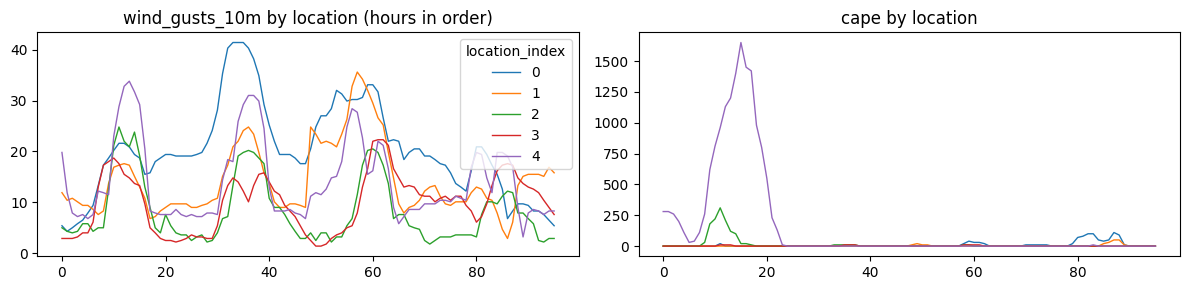

In [7]:
def longest_run(series):
    best = cur = 1
    for a, b in zip(series.values[:-1], series.values[1:]):
        cur = cur + 1 if a == b else 1
        best = max(best, cur)
    return best

w = weather.sort_values(["location_index", "observed_at"])
runs = (w.groupby("location_index")[["wind_speed_10m","wind_gusts_10m","cape"]]
          .agg(longest_run).rename(columns=lambda c: "longest_identical_run_" + c))
print(runs)
print("(note: 0.0 is a natural repeated value for cape and precipitation; wind runs are the informative ones)")

w["d_speed"] = w.groupby("location_index").wind_speed_10m.diff().abs()
print("\nLargest hour-to-hour wind speed change per location (km/h):")
print(w.groupby("location_index").d_speed.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for loc, g in w.groupby("location_index"):
    axes[0].plot(range(len(g)), g.wind_gusts_10m.values, label=str(loc), lw=1)
    axes[1].plot(range(len(g)), g.cape.values, label=str(loc), lw=1)
axes[0].set_title("wind_gusts_10m by location (hours in order)"); axes[1].set_title("cape by location")
axes[0].legend(title="location_index"); plt.tight_layout(); plt.show()

## 7. Invalid values (family 2): rules
Each rule is a query that must return 0 if the data is valid. Rules are about what cannot be true.

In [8]:
BBOX = (36.0, 26.0, 42.0, 45.0)   # lamin, lomin, lamax, lomax from OPENSKY_BBOX
checks = {
    "latitude outside bbox": int(((state.latitude < BBOX[0]) | (state.latitude > BBOX[2])).sum()),
    "longitude outside bbox": int(((state.longitude < BBOX[1]) | (state.longitude > BBOX[3])).sum()),
    "negative velocity": int((state.velocity < 0).sum()),
    "true_track outside 0..360": int(((state.true_track < 0) | (state.true_track > 360)).sum()),
    "negative baro_altitude": int((state.baro_altitude < 0).sum()),
    "baro_altitude above 20,000 m": int((state.baro_altitude > 20000).sum()),
    "last_contact before time_position": int((state.last_contact < state.time_position).sum()),
    "time_position later than retrieved_at (any amount)": int((state.time_position > state.retrieved_at).sum()),
    "time_position more than 60 s later than retrieved_at": int(((pd.to_datetime(state.time_position) - pd.to_datetime(state.retrieved_at)).dt.total_seconds() > 60).sum()),
    "squawk not 4 octal digits": int((~state.squawk.dropna().str.fullmatch("[0-7]{4}")).sum()),
    "weather: negative values": int((weather[["wind_speed_10m","wind_gusts_10m","precipitation","showers","cape"]] < 0).sum().sum()),
    "weather: gust below mean wind speed": int((weather.wind_gusts_10m < weather.wind_speed_10m).sum()),
    "weather: showers above precipitation": int((weather.showers > weather.precipitation).sum()),
}
print(pd.Series(checks, name="rows violating the rule").to_string())

latitude outside bbox                                     0
longitude outside bbox                                    0
negative velocity                                         0
true_track outside 0..360                                 0
negative baro_altitude                                    0
baro_altitude above 20,000 m                              0
last_contact before time_position                         0
time_position later than retrieved_at (any amount)      472
time_position more than 60 s later than retrieved_at      0
squawk not 4 octal digits                                 0
weather: negative values                                  0
weather: gust below mean wind speed                       0
weather: showers above precipitation                      0


## 8. Failures across fields (family 4): compare columns

In [9]:
air = state[state.on_ground == 0]
gnd = state[state.on_ground == 1]
print("On ground:", len(gnd), "rows; of these baro_altitude NULL:", int(gnd.baro_altitude.isna().sum()),
      "; velocity above 50 m/s (180 km/h):", int((gnd.velocity > 50).sum()))
print("Airborne rows with NULL or <= 0 baro_altitude:", int((air.baro_altitude.isna() | (air.baro_altitude <= 0)).sum()))
state["alt_gap"] = (state.geo_altitude - state.baro_altitude).abs()
print("\n|geo_altitude - baro_altitude| (m): median %.0f, 95th pct %.0f, max %.0f" % (
      state.alt_gap.median(), state.alt_gap.quantile(.95), state.alt_gap.max()))
print("Rows with a gap above 1,000 m:", int((state.alt_gap > 1000).sum()))
print(state.loc[state.alt_gap > 1000, ["icao24","on_ground","baro_altitude","geo_altitude","velocity","retrieved_at"]].head(8))
print("\nspi = 1 (special purpose indicator) rows:", int((state.spi == 1).sum()))
age = (pd.to_datetime(state.retrieved_at) - pd.to_datetime(state.time_position)).dt.total_seconds()
print("\nAge of a state at retrieval (s): median %.0f, 95th pct %.0f, max %.0f, min %.0f" % (
      age.median(), age.quantile(.95), age.max(), age.min()))

On ground: 42 rows; of these baro_altitude NULL: 40 ; velocity above 50 m/s (180 km/h): 4
Airborne rows with NULL or <= 0 baro_altitude: 2

|geo_altitude - baro_altitude| (m): median 274, 95th pct 434, max 9258
Rows with a gap above 1,000 m: 2
     icao24  on_ground  baro_altitude  geo_altitude  velocity          retrieved_at
246  73828a          0         1333.5      10591.80    245.21  2026-10-20T10:14:56Z
268  152073          0        10248.9      11490.96    254.09  2026-10-20T10:14:56Z

spi = 1 (special purpose indicator) rows: 12

Age of a state at retrieval (s): median -1, 95th pct 239, max 3622, min -3


## 9. Unusual values (family 3): robust methods, per entity
IQR fences and robust z-score (median and MAD), per location. Flag and look; do not delete. Never mean ± 3 SD.

In [10]:
def iqr_flag(g, col):
    q1, q3 = g[col].quantile([.25, .75]); iqr = q3 - q1
    return (g[col] < q1 - 1.5 * iqr) | (g[col] > q3 + 1.5 * iqr)

def robust_z(g, col):
    med = g[col].median(); mad = (g[col] - med).abs().median()
    return (g[col] - med) / (1.4826 * mad) if mad > 0 else g[col] * 0

out = []
for col in ["wind_gusts_10m", "cape"]:
    for loc, g in weather.groupby("location_index"):
        out.append({"variable": col, "location_index": loc,
                    "iqr_flagged": int(iqr_flag(g, col).sum()),
                    "robust_z_above_3.5": int((robust_z(g, col) > 3.5).sum()),
                    "max": g[col].max()})
print(pd.DataFrame(out).to_string(index=False))
print("(cape is 0 most of the time, so the IQR is 0 and every non-zero hour is flagged, while MAD = 0 gives no robust z at all: "
      "these methods need a different treatment for zero-inflated variables)")
print("\nLook at what is flagged before believing it (hours of the highest gusts):")
print(weather.sort_values("wind_gusts_10m", ascending=False)[["location_index","observed_at","wind_speed_10m","wind_gusts_10m","cape"]].head(8))
print("\nAircraft velocity per origin: IQR flagged (all aircraft together):",
      int(iqr_flag(state.dropna(subset=['velocity']), 'velocity').sum()))

      variable  location_index  iqr_flagged  robust_z_above_3.5    max
wind_gusts_10m               0            5                   0   41.4
wind_gusts_10m               1            5                   5   35.6
wind_gusts_10m               2            2                  14   24.8
wind_gusts_10m               3            0                   0   22.3
wind_gusts_10m               4            0                   9   33.8
          cape               0           22                   0  110.0
          cape               1            9                   0   50.0
          cape               2           17                   0  310.0
          cape               3           10                   0   10.0
          cape               4           23                   0 1650.0
(cape is 0 most of the time, so the IQR is 0 and every non-zero hour is flagged, while MAD = 0 gives no robust z at all: these methods need a different treatment for zero-inflated variables)

Look at what is flagged bef

## 10. Identity (family 6): one thing as two, two as one

In [11]:
cs = state.assign(cs=state.callsign.str.strip()).dropna(subset=["cs"])
cs = cs[cs.cs != ""]
multi_cs = cs.groupby("icao24").cs.nunique()
print("icao24 with more than one callsign:", int((multi_cs > 1).sum()), "of", cs.icao24.nunique())
print(cs[cs.icao24.isin(multi_cs[multi_cs > 1].index[:3])].groupby("icao24").cs.unique())
multi_ac = cs.groupby("cs").icao24.nunique()
print("\ncallsigns used by more than one icao24:", int((multi_ac > 1).sum()))
print(multi_ac[multi_ac > 1].head(8))
print("\nlocations (should be 5 distinct places):")
print(location[["location_index","latitude","longitude","elevation"]])
print("\nicao24 that appear as both airborne and on-ground in different rows:",
      int((state.groupby("icao24").on_ground.nunique() > 1).sum()))

icao24 with more than one callsign: 20 of 461
icao24
151e1b     [PBD840, PBD798]
486648    [CND5259, CND5GF]
4ba90c     [THY7NQ, THY44D]
Name: cs, dtype: object

callsigns used by more than one icao24: 1
cs
PALAZ03    2
Name: icao24, dtype: int64

locations (should be 5 distinct places):
   location_index   latitude  longitude  elevation
0               0  41.258053  28.772957       57.0
1               1  40.886364  29.251366       93.0
2               2  40.119682  32.952980      948.0
3               3  38.287888  27.128910      120.0
4               4  36.908600  30.838587       59.0

icao24 that appear as both airborne and on-ground in different rows: 13


## 11. Notes to carry into the issues register
Fill in after running (this cell is for the team): which checks found something, which found nothing (write the check name and the result), and a first guess for the cause with confirmed / inferred / unknown.